# Event Horizon — small-size reproduction notebook

Finite-dimensional quantum-information toy models related to the black hole information paradox.
**This notebook does not solve, and does not claim to solve, the information paradox.** No gravity is simulated.
The island formula appears only in the paper (`paper/event_horizon.md`) as a separate theoretical section; the single
"two-candidate minimum" plot at the end is a labelled toy illustration, not a derivation.

Everything here runs on CPU with numpy/scipy in under 3 minutes and re-derives, at small sizes, the main results that
were produced at larger sizes on a Lambda A100 40 GB (GPU 0). Where the stored GPU results (`../results/*.json`) are
present they are loaded for comparison only.

Conventions: entropies in nats (bits = nats / ln 2); eigenvalues are clipped at `CLIP = 1e-14` before the logarithm
(never `log 0`); every random number comes from `numpy.random.default_rng(SEED + tag)` with the seeds printed below.
Finding classes: 1 reproduction, 2 verification of a known relation, 3 new computational observation within an
existing model, 4 new conjecture, 5 potentially novel result needing investigation. Nothing here is above class 3.

In [1]:
import json, math, os, time
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
T0 = time.time()
SEED, CLIP, LN2 = 20261115, 1e-14, math.log(2.0)
BG, FG, CYAN, AMBER, MAGENTA, GREEN = "#07080B", "#E6EDF3", "#3DF5FF", "#FFB547", "#FF5DA8", "#6CF29A"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": FG,
                     "axes.labelcolor": FG, "axes.edgecolor": FG, "xtick.color": FG, "ytick.color": FG,
                     "legend.facecolor": BG, "legend.edgecolor": "#30363D", "grid.color": "#21262D", "figure.dpi": 110})
RES = os.path.join("..", "results")
SUMMARY = {"seed_base": SEED, "clip": CLIP, "units": "nats", "numpy": np.__version__}
def rng(tag): return np.random.default_rng(SEED + tag)
def vn(p):
    p = np.asarray(p, float); p = p[p > CLIP]
    return float(-(p * np.log(p)).sum())
def page(m, n):
    "Page 1993: <S> = sum_{j=n+1}^{mn} 1/j - (m-1)/(2n), m <= n (nats)."
    if m > n: m, n = n, m
    return math.fsum(1.0 / j for j in range(n + 1, m * n + 1)) - (m - 1) / (2.0 * n)
def haar_unitary(d, g):
    "QR of a complex Ginibre matrix with the phase fix of Mezzadri (2007)."
    z = (g.standard_normal((d, d)) + 1j * g.standard_normal((d, d))) / math.sqrt(2)
    q, r = np.linalg.qr(z); ph = np.diagonal(r) / np.abs(np.diagonal(r))
    return q * ph
def haar_state(d, g):
    v = g.standard_normal(d) + 1j * g.standard_normal(d)
    return v / np.linalg.norm(v)
def schmidt_S(psi, dA, dB):
    return vn(np.linalg.svd(psi.reshape(dA, dB), compute_uv=False) ** 2)
def load(name):
    f = os.path.join(RES, name)
    return json.load(open(f)) if os.path.exists(f) else None
print("numpy", np.__version__, "| seed base", SEED, "| clip", CLIP)

numpy 1.26.4 | seed base 20261115 | clip 1e-14


## 1. Page curve of a Haar-random pure state (Problem A; class 1 reproduction / class 2 verification)

$N$ qubits, radiation $R$ = first $k$ qubits. Prediction (Page 1993; proven by Foong-Kanno 1994, Sanchez-Ruiz 1995, Sen 1996):
$\langle S(R_k)\rangle = \sum_{j=n+1}^{mn} 1/j - (m-1)/(2n)$ with $m = 2^{\min(k,N-k)}$, $n = 2^{\max(k,N-k)}$.

N=10, 300 Haar states, seed 20261116
k      : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Page   : [0.     0.6917 1.379  2.0487 2.6481 2.9663 2.6481 2.0487 1.379  0.6917
 0.    ]
MC mean: [0.     0.6916 1.3788 2.0486 2.6493 2.9652 2.6477 2.0486 1.3789 0.6916
 0.    ]
max|z| = 2.01   max|mean-Page| = 1.16e-03 nats   max|S(R)-S(B)| = 1.3e-15
half cut: Page = 2.9663 nats = 4.2795 bits; deficit from (N/2) ln2 = 0.4994 nats


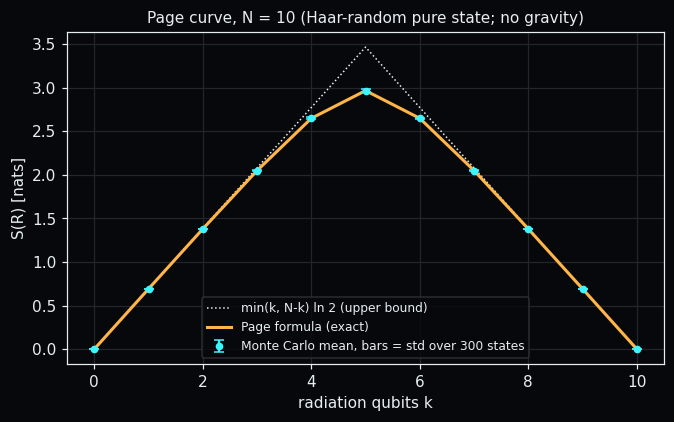

In [2]:
N, NS = 10, 300
g = rng(1); S = np.zeros((NS, N + 1)); dSB = 0.0
for s in range(NS):
    psi = haar_state(2 ** N, g)
    for k in range(1, N):
        M = psi.reshape(2 ** k, 2 ** (N - k))
        S[s, k] = vn(np.linalg.svd(M, compute_uv=False) ** 2)
        if s < 10:   # independent check S(R) = S(B) from the two reduced density matrices
            dSB = max(dSB, abs(vn(np.linalg.eigvalsh(M @ M.conj().T)) - vn(np.linalg.eigvalsh(M.T @ M.conj()))))
pg = np.array([page(2 ** k, 2 ** (N - k)) for k in range(N + 1)])
mean, sd = S.mean(0), S.std(0, ddof=1); se = sd / math.sqrt(NS)
z = (mean[1:N] - pg[1:N]) / se[1:N]
print(f"N={N}, {NS} Haar states, seed {SEED+1}")
print("k      :", list(range(N + 1)))
print("Page   :", np.round(pg, 4)); print("MC mean:", np.round(mean, 4))
print(f"max|z| = {np.abs(z).max():.2f}   max|mean-Page| = {np.abs(mean-pg).max():.2e} nats   max|S(R)-S(B)| = {dSB:.1e}")
print(f"half cut: Page = {pg[N//2]:.4f} nats = {pg[N//2]/LN2:.4f} bits; deficit from (N/2) ln2 = {N/2*LN2-pg[N//2]:.4f} nats")
SUMMARY["A"] = {"N": N, "states": NS, "seed": SEED + 1, "max_abs_z": float(np.abs(z).max()),
                "max_abs_dev_nats": float(np.abs(mean - pg).max()), "max_SR_minus_SB": dSB}
fig, ax = plt.subplots(figsize=(7, 4)); k = np.arange(N + 1)
ax.plot(k, np.minimum(k, N - k) * LN2, ":", color=FG, lw=1, label="min(k, N-k) ln 2 (upper bound)")
ax.plot(k, pg, "-", color=AMBER, lw=2, label="Page formula (exact)")
ax.errorbar(k, mean, yerr=sd, fmt="o", color=CYAN, ms=4, capsize=3, label=f"Monte Carlo mean, bars = std over {NS} states")
ax.set_xlabel("radiation qubits k"); ax.set_ylabel("S(R) [nats]"); ax.legend(fontsize=8); ax.grid(True)
ax.set_title(f"Page curve, N = {N} (Haar-random pure state; no gravity)", fontsize=10); plt.show()

## 2. Page's theorem at several (m, n) (Problem B; class 2)
Exact formula versus Monte Carlo and versus the asymptotic forms $\ln m - m/(2n)$ and $\ln m - m/(2n) + 1/(2mn)$.

In [3]:
rows = []
print(f"{'m':>3} {'n':>4} {'samples':>7} {'exact':>9} {'MC mean':>9} {'stderr':>8} {'z':>6} {'asym0 err':>10} {'asym1 err':>10}")
for i, (m, n, ns) in enumerate([(2, 2, 4000), (2, 8, 4000), (3, 5, 4000), (4, 4, 4000), (8, 16, 3000), (16, 16, 2000), (32, 64, 600)]):
    g = rng(100 + i)
    Ss = np.array([schmidt_S(haar_state(m * n, g), m, n) for _ in range(ns)])
    ex = page(m, n); mu, se_ = Ss.mean(), Ss.std(ddof=1) / math.sqrt(ns)
    a0 = math.log(m) - m / (2 * n); a1 = a0 + 1 / (2 * m * n)
    rows.append({"m": m, "n": n, "samples": ns, "exact": ex, "mc": mu, "stderr": se_, "z": (mu - ex) / se_})
    print(f"{m:3d} {n:4d} {ns:7d} {ex:9.5f} {mu:9.5f} {se_:8.5f} {(mu-ex)/se_:6.2f} {a0-ex:10.2e} {a1-ex:10.2e}")
print("max |z| =", round(max(abs(r["z"]) for r in rows), 2), "| seeds", SEED + 100, "..", SEED + 106)
SUMMARY["B"] = {"rows": rows, "max_abs_z": max(abs(r["z"]) for r in rows)}
b = load("b_page_theorem.json")
if b: print(f"stored A100 run: {b['n_pairs']} (m,n) pairs up to m*n = {b['max_dim']}, max|z| = {b['max_abs_z']:.2f}, rms z = {b['z_rms']:.2f}")

  m    n samples     exact   MC mean   stderr      z  asym0 err  asym1 err
  2    2    4000   0.33333   0.33132  0.00284  -0.71  -1.40e-01  -1.52e-02


  2    8    4000   0.60037   0.60029  0.00107  -0.08  -3.22e-02  -9.75e-04
  3    5    4000   0.83490   0.83482  0.00166  -0.05  -3.63e-02  -2.95e-03


  4    4    4000   0.92240   0.92386  0.00182   0.80  -3.61e-02  -4.85e-03


  8   16    3000   1.83367   1.83212  0.00070  -2.21  -4.23e-03  -3.20e-04
 16   16    2000   2.27487   2.27557  0.00068   1.03  -2.28e-03  -3.24e-04


 32   64     600   3.21600   3.21572  0.00040  -0.70  -2.64e-04  -2.03e-05
max |z| = 2.21 | seeds 20261215 .. 20261221
stored A100 run: 124 (m,n) pairs up to m*n = 16777216, max|z| = 2.69, rms z = 1.00


## 3. Sequential evaporation with a fresh Haar unitary per step (Problem C; class 2)
Start in $|0\ldots0\rangle$; at step $t$ apply a fresh Haar unitary to the $N-t$ remaining hole qubits, then emit one qubit.
Prediction (left-invariance of the Haar measure, see paper Sec. 4.4): the state is exactly Haar at every step, so the mean
is Page's formula with no correction, and consecutive steps are correlated because they are nested cuts of one state.

In [4]:
N, NT = 8, 150
g = rng(200); S = np.zeros((NT, N + 1)); dSB = 0.0
for s in range(NT):
    psi = np.zeros(2 ** N, complex); psi[0] = 1.0
    for t in range(N):
        nrem = N - t
        psi = (haar_unitary(2 ** nrem, g) @ psi.reshape(2 ** nrem, 2 ** t)).reshape(-1)   # rows: hole, cols: radiation
        M = psi.reshape(2 ** (nrem - 1), 2 ** (t + 1))
        S[s, t + 1] = vn(np.linalg.eigvalsh(M.T @ M.conj()))            # rho_R
        dSB = max(dSB, abs(S[s, t + 1] - vn(np.linalg.eigvalsh(M @ M.conj().T))))   # rho_B, independently
pg = np.array([page(2 ** t, 2 ** (N - t)) for t in range(N + 1)])
mean, sd = S.mean(0), S.std(0, ddof=1); se = sd / math.sqrt(NT)
z = (mean[1:N] - pg[1:N]) / se[1:N]
corr = [float(np.corrcoef(S[:, t], S[:, t + 1])[0, 1]) for t in range(1, N - 1)]
print(f"N={N}, {NT} trajectories, seed {SEED+200}")
print("Page   :", np.round(pg, 4)); print("MC mean:", np.round(mean, 4)); print("z      :", np.round(z, 2))
print(f"max|z| = {np.abs(z).max():.2f}   max|S(R)-S(B)| = {dSB:.1e}   consecutive-step correlation: {np.round(corr, 2)}")
SUMMARY["C"] = {"N": N, "trajectories": NT, "seed": SEED + 200, "max_abs_z": float(np.abs(z).max()),
                "max_SR_minus_SB": dSB, "corr_consecutive": corr}
c = load("c_evap_full_N8.json")
if c: print("stored builder run (full, N=8) mean:", np.round(c["S_R_mean"], 4))
S_C, pg_C = mean.copy(), pg.copy()

N=8, 150 trajectories, seed 20261315
Page   : [0.     0.6873 1.357  1.9565 2.2749 1.9565 1.357  0.6873 0.    ]
MC mean: [0.     0.6872 1.3573 1.9585 2.2783 1.9552 1.3562 0.6871 0.    ]
z      : [-0.2   0.33  1.25  1.37 -0.83 -0.93 -0.53]
max|z| = 1.37   max|S(R)-S(B)| = 1.8e-15   consecutive-step correlation: [0.48 0.46 0.49 0.41 0.43 0.43]
stored builder run (full, N=8) mean: [0.6873 1.3578 1.9586 2.2736 1.9583 1.3581 0.6871 0.    ]


## 4. Bell-pair "Hawking" toy model versus the unitary model (Problem D; class 1)
$k$ independent Bell pairs, one half of each kept inside: $\rho_R = (I/2)^{\otimes k}$, $S(R) = k\ln 2$ exactly, never turning over.
If the remaining hole is assigned capacity $(N-k)\ln 2$ (a modelling assumption of the toy), the pair model exceeds it for $k > N/2$.

k=0: S(R) = 0.000000000000 nats = 0.000000 bits, |S - k ln2| = 0.0e+00, max dev from flat spectrum = 0.0e+00
k=1: S(R) = 0.693147180560 nats = 1.000000 bits, |S - k ln2| = 1.1e-16, max dev from flat spectrum = 1.1e-16
k=2: S(R) = 1.386294361120 nats = 2.000000 bits, |S - k ln2| = 2.2e-16, max dev from flat spectrum = 1.1e-16
k=3: S(R) = 2.079441541680 nats = 3.000000 bits, |S - k ln2| = 4.4e-16, max dev from flat spectrum = 5.6e-17
k=4: S(R) = 2.772588722240 nats = 4.000000 bits, |S - k ln2| = 8.9e-16, max dev from flat spectrum = 4.2e-17
k=5: S(R) = 3.465735902800 nats = 5.000000 bits, |S - k ln2| = 1.8e-15, max dev from flat spectrum = 2.4e-17
k=6: S(R) = 4.158883083360 nats = 6.000000 bits, |S - k ln2| = 2.7e-15, max dev from flat spectrum = 1.4e-17


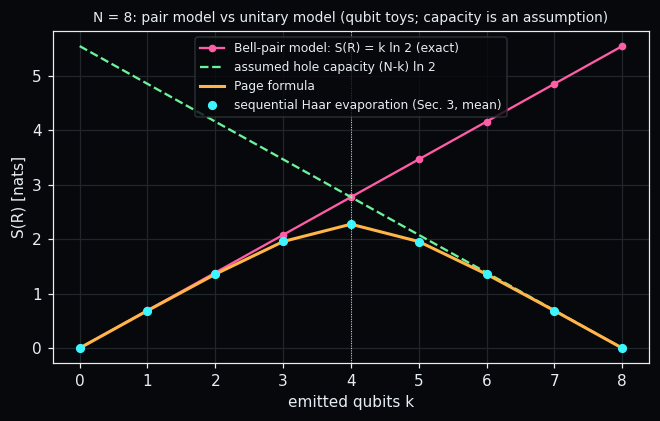

first k where the pair model exceeds the assumed capacity: 5 (= N/2 + 1)


In [5]:
errs = []
for k in range(0, 7):
    bell = np.array([1, 0, 0, 1]) / math.sqrt(2); psi = np.array([1.0])
    for _ in range(k): psi = np.kron(psi, bell)                       # qubit order r1 p1 r2 p2 ...
    T = psi.reshape((2,) * (2 * k)) if k else psi
    if k:
        T = np.transpose(T, list(range(0, 2 * k, 2)) + list(range(1, 2 * k, 2))).reshape(2 ** k, 2 ** k)   # radiation | partners
        ev = np.linalg.eigvalsh(T @ T.conj().T); Sk = vn(ev); flat = float(np.abs(ev - 2.0 ** -k).max())
    else: Sk, flat = 0.0, 0.0
    errs.append(abs(Sk - k * LN2))
    print(f"k={k}: S(R) = {Sk:.12f} nats = {Sk/LN2:.6f} bits, |S - k ln2| = {errs[-1]:.1e}, max dev from flat spectrum = {flat:.1e}")
SUMMARY["D"] = {"max_abs_err": max(errs)}
N = 8; k = np.arange(N + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k, k * LN2, "-o", color=MAGENTA, ms=4, label="Bell-pair model: S(R) = k ln 2 (exact)")
ax.plot(k, (N - k) * LN2, "--", color=GREEN, label="assumed hole capacity (N-k) ln 2")
ax.plot(k, pg_C, "-", color=AMBER, lw=2, label="Page formula")
ax.plot(k, S_C, "o", color=CYAN, ms=5, label="sequential Haar evaporation (Sec. 3, mean)")
ax.axvline(N / 2, color=FG, lw=0.6, ls=":"); ax.set_xlabel("emitted qubits k"); ax.set_ylabel("S(R) [nats]")
ax.legend(fontsize=8); ax.grid(True); ax.set_title("N = 8: pair model vs unitary model (qubit toys; capacity is an assumption)", fontsize=9); plt.show()
print("first k where the pair model exceeds the assumed capacity:", int(np.argmax(k * LN2 > (N - k) * LN2)), "(= N/2 + 1)")

## 5. Local scramblers: brickwork depth per emission (Extension E1; class 3 observation inside a known model)
Instead of a Haar unitary on the whole hole, apply `depth` brickwork layers of Haar-random 2-qubit gates on the remaining
open chain before each emission. Quantity: $\max_t(\text{Page}(t) - \langle S(R_t)\rangle)$. Also: scrambled **stabilizer**
states (random Clifford circuits) have flat spectra, integer-bit entropies, and a mean half-cut entropy *below* Page.

N=8, 48 seeds per depth, seed 20261615+depth;   max over t of (Page - <S>), nats


depth  1: max deviation = 1.0747 +- 0.0507 (95% CI) at t = 4   | stored A100 run (256 seeds): 1.0961 +- 0.0229


depth  2: max deviation = 0.7424 +- 0.0457 (95% CI) at t = 3   | stored A100 run (256 seeds): 0.7252 +- 0.0206


depth  4: max deviation = 0.2129 +- 0.0285 (95% CI) at t = 3   | stored A100 run (256 seeds): 0.2468 +- 0.0129


depth  8: max deviation = 0.0401 +- 0.0105 (95% CI) at t = 2   | stored A100 run (256 seeds): 0.0559 +- 0.0060


depth 16: max deviation = 0.0048 +- 0.0060 (95% CI) at t = 3   | stored A100 run (256 seeds): 0.0029 +- 0.0009


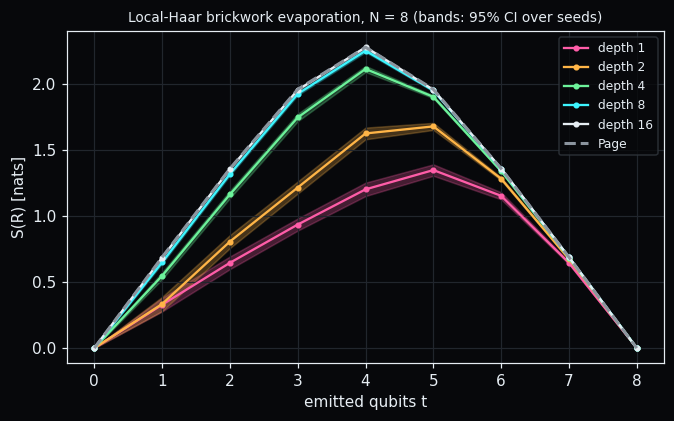

In [6]:
def apply_2q(st, gate, i):
    t = np.tensordot(gate.reshape(2, 2, 2, 2), st, axes=([2, 3], [i, i + 1]))
    return np.moveaxis(t, [0, 1], [i, i + 1])
N, NSD = 8, 48
pg = np.array([page(2 ** t, 2 ** (N - t)) for t in range(N + 1)])
e1 = load("e1_scrambling.json"); out = {}
print(f"N={N}, {NSD} seeds per depth, seed {SEED+500}+depth;   max over t of (Page - <S>), nats")
fig, ax = plt.subplots(figsize=(7, 4)); cols = [MAGENTA, AMBER, GREEN, CYAN, FG]
for ci, depth in enumerate([1, 2, 4, 8, 16]):
    g = rng(500 + depth); S = np.zeros((NSD, N + 1))
    for s in range(NSD):
        st = np.zeros((2,) * N, complex); st[(0,) * N] = 1.0; layer = 0
        for t in range(N):
            nrem = N - t
            for _ in range(depth):
                for i in range(layer % 2, nrem - 1, 2): st = apply_2q(st, haar_unitary(4, g), i)
                layer += 1
            S[s, t + 1] = schmidt_S(st.reshape(-1), 2 ** (nrem - 1), 2 ** (t + 1))
    mean = S.mean(0); ci95 = 1.96 * S.std(0, ddof=1) / math.sqrt(NSD)
    dev = pg - mean; it = int(dev.argmax()); out[depth] = (float(dev[it]), float(ci95[it]))
    ref = ""
    if e1:
        r = [r for r in e1["runs"] if r["N"] == N and r["family"] == "local_haar" and r["depth"] == depth][0]
        ref = f"   | stored A100 run ({r['n_seeds']} seeds): {r['max_dev_from_page']:.4f} +- {r['max_dev_ci95']:.4f}"
    print(f"depth {depth:2d}: max deviation = {dev[it]:.4f} +- {ci95[it]:.4f} (95% CI) at t = {it}{ref}")
    ax.plot(range(N + 1), mean, "-o", ms=3, color=cols[ci], label=f"depth {depth}")
    ax.fill_between(range(N + 1), mean - ci95, mean + ci95, color=cols[ci], alpha=0.25)
ax.plot(range(N + 1), pg, "--", color="#8B949E", lw=2, label="Page"); ax.set_xlabel("emitted qubits t"); ax.set_ylabel("S(R) [nats]")
ax.legend(fontsize=8); ax.grid(True); ax.set_title("Local-Haar brickwork evaporation, N = 8 (bands: 95% CI over seeds)", fontsize=9); plt.show()
SUMMARY["E1_local_haar_max_dev"] = {str(d): v for d, v in out.items()}

In [7]:
# Stabilizer states from deep random Clifford brickwork (each 2-qubit gate = word of 12 random generators)
H = np.array([[1, 1], [1, -1]]) / math.sqrt(2); Sg = np.diag([1, 1j]); I2 = np.eye(2)
CX = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], complex)
SW = np.array([[1, 0, 0, 0], [0, 0, 1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], complex)
gens = [np.kron(H, I2), np.kron(I2, H), np.kron(Sg, I2), np.kron(I2, Sg), CX, SW @ CX @ SW]
N, LAYERS, NSC = 8, 40, 200
g = rng(600); half = np.zeros(NSC); flat_err = 0.0
for s in range(NSC):
    st = np.zeros((2,) * N, complex); st[(0,) * N] = 1.0
    for layer in range(LAYERS):
        for i in range(layer % 2, N - 1, 2):
            gate = np.eye(4, dtype=complex)
            for w in g.integers(0, 6, size=12): gate = gens[w] @ gate
            st = apply_2q(st, gate, i)
    p = np.linalg.svd(st.reshape(2 ** (N // 2), -1), compute_uv=False) ** 2; p = p[p > 1e-10]
    half[s] = vn(p); flat_err = max(flat_err, abs(half[s] + math.log((p ** 2).sum())))
pgh = page(2 ** (N // 2), 2 ** (N // 2)); mu, se_ = half.mean(), half.std(ddof=1) / math.sqrt(NSC)
vals, cnt = np.unique(np.round(half / LN2).astype(int), return_counts=True)
print(f"N={N}, {NSC} stabilizer states, {LAYERS} layers, seed {SEED+600}")
print(f"half-cut <S> = {mu:.4f} +- {se_:.4f} nats (stderr);  Page = {pgh:.4f};  stabilizer - Page = {mu-pgh:+.4f} nats ({(mu-pgh)/se_:+.1f} stderr)")
print("half-cut entropy histogram (bits: count):", dict(zip(vals.tolist(), cnt.tolist())), "| max |vN - Renyi2| =", f"{flat_err:.1e}")
print(f"mean purity = {np.exp(-half).mean():.5f} vs Haar (m+n)/(mn+1) = {2*2**(N//2)/(4**(N//2)+1):.5f}  (2-design check)")
SUMMARY["E1_clifford"] = {"N": N, "states": NSC, "half_mean": mu, "stderr": se_, "page": pgh, "minus_page": mu - pgh,
                          "hist_bits": dict(zip(vals.tolist(), cnt.tolist())), "max_vn_minus_r2": flat_err}

N=8, 200 stabilizer states, 40 layers, seed 20261715
half-cut <S> = 2.1384 +- 0.0321 nats (stderr);  Page = 2.2749;  stabilizer - Page = -0.1365 nats (-4.2 stderr)
half-cut entropy histogram (bits: count): {1: 1, 2: 32, 3: 116, 4: 51} | max |vN - Renyi2| = 3.7e-13
mean purity = 0.13094 vs Haar (m+n)/(mn+1) = 0.12451  (2-design check)


## 6. Hayden-Preskill recovery, old black hole, Haar scrambler (Extension E2; class 2)
Diary $A$ ($k$ qubits) maximally entangled with reference $R$; hole $B$ ($n_B$ qubits) maximally entangled with early radiation $E$;
Haar $U$ on $A B$; the last $m$ output qubits $D$ are emitted, $B'$ remains. Derived prediction (paper Sec. 4.6):
$\mathbb{E}\,T \le \tfrac12\sqrt{(d_R^2-1)(d_D^{-2}-d^{-2})/(1-d^{-2})} \le \tfrac12\,2^{k-m}$ with $T = \tfrac12\lVert\rho_{RB'}-\rho_R\otimes\rho_{B'}\rVert_1$,
independent of $n_B$; $I(R{:}ED) + I(R{:}B') = 2k\ln 2$.

k=1, n_B=4, 120 Haar unitaries, seed 20261515;  2k ln2 = 1.3863 nats
 m   I(R:ED)    +-se  I(R:Bp)       T    +-se   bound 1/2*2^(k-m)   F_EPR
 0    0.0000  0.0000   1.3863  0.7500  0.0000  0.8660      1.0000  0.2500
 1    0.9769  0.0015   0.4094  0.3727  0.0008  0.4324      0.5000  0.5724
 2    1.2914  0.0009   0.0949  0.1835  0.0010  0.2149      0.2500  0.8433
 3    1.3644  0.0004   0.0219  0.0888  0.0009  0.1049      0.1250  0.9584
 4    1.3821  0.0002   0.0042  0.0380  0.0010  0.0469      0.0625  0.9918
 5    1.3863  0.0000   0.0000  0.0000  0.0000  0.0000      0.0312  1.0000
decoupling bound holds on the mean: True | max |I(R:ED)+I(R:B')-2k ln2| = 6.7e-16 | thresholds: {'m_I90': 2, 'm_I99': 4, 'm_T10': 3}
stored A100 run I(R:ED): [-0.      0.9769  1.2923  1.3644  1.3821  1.3863] thresholds {'m_I90': 2, 'm_I99': 4, 'm_T10': 3, 'm_F90': 2}


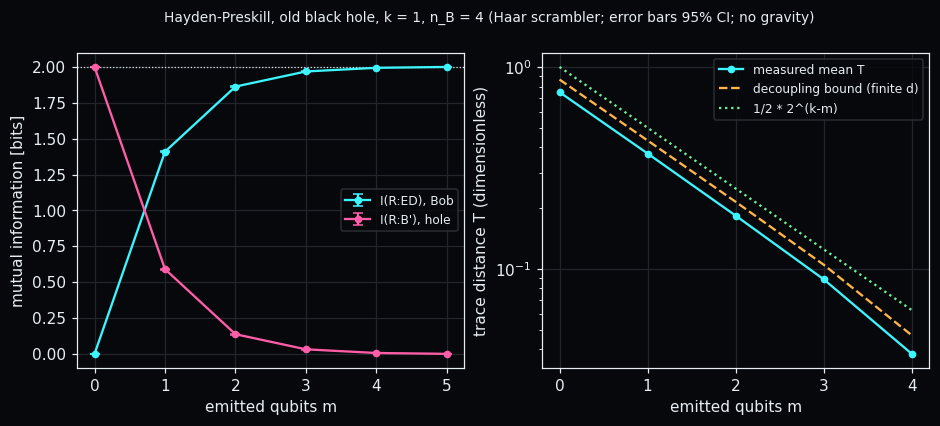

In [8]:
kq, nB, NSH = 1, 4, 120
n = kq + nB; d, dR, dE = 2 ** n, 2 ** kq, 2 ** nB
g = rng(400); ms = list(range(n + 1)); keys = ("I_R_ED", "I_R_Bp", "T", "F_EPR")
acc = {q: np.zeros((NSH, len(ms))) for q in keys}
for s in range(NSH):
    U = haar_unitary(d, g)
    for mi, m in enumerate(ms):
        dD, dBp = 2 ** m, 2 ** (n - m)
        Tn = U.reshape(dBp, dD, dR, dE) / math.sqrt(d)                       # [b', d, r, e]
        rho_RBp = np.einsum("bdre,cdse->rbsc", Tn, Tn.conj()).reshape(dR * dBp, dR * dBp)
        rho_R = np.einsum("bdre,bdse->rs", Tn, Tn.conj()); rho_Bp = np.einsum("bdre,cdre->bc", Tn, Tn.conj())
        S_R, S_Bp, S_RBp = vn(np.linalg.eigvalsh(rho_R)), vn(np.linalg.eigvalsh(rho_Bp)), vn(np.linalg.eigvalsh(rho_RBp))
        acc["I_R_ED"][s, mi] = S_R + S_RBp - S_Bp          # global purity: S(ED) = S(RB'), S(RED) = S(B')
        acc["I_R_Bp"][s, mi] = S_R + S_Bp - S_RBp
        acc["T"][s, mi] = 0.5 * np.abs(np.linalg.eigvalsh(rho_RBp - np.kron(rho_R, rho_Bp))).sum()
        # Yoshida-Kitaev probabilistic decoder, simulated literally (apply U*, project D D' on a Bell pair)
        amp = np.einsum("bdre,cfse->rbdcfs", Tn, U.conj().reshape(dBp, dD, dR, dE)) / math.sqrt(dR)
        Phi = np.einsum("rbdcds->rbcs", amp) / math.sqrt(dD); P = float(np.real(np.vdot(Phi, Phi)))
        ov = np.einsum("rbcr->bc", Phi) / math.sqrt(dR); acc["F_EPR"][s, mi] = float(np.real(np.vdot(ov, ov))) / P
mean = {q: acc[q].mean(0) for q in keys}; se = {q: acc[q].std(0, ddof=1) / math.sqrt(NSH) for q in keys}
bound = [0.5 * math.sqrt((dR ** 2 - 1) * (4.0 ** -m - 1.0 / d ** 2) / (1 - 1.0 / d ** 2)) for m in ms]
print(f"k={kq}, n_B={nB}, {NSH} Haar unitaries, seed {SEED+400};  2k ln2 = {2*kq*LN2:.4f} nats")
print(f"{'m':>2} {'I(R:ED)':>9} {'+-se':>7} {'I(R:Bp)':>8} {'T':>7} {'+-se':>7} {'bound':>7} {'1/2*2^(k-m)':>11} {'F_EPR':>7}")
for i, m in enumerate(ms):
    print(f"{m:2d} {mean['I_R_ED'][i]:9.4f} {se['I_R_ED'][i]:7.4f} {mean['I_R_Bp'][i]:8.4f} {mean['T'][i]:7.4f} {se['T'][i]:7.4f} {bound[i]:7.4f} {0.5*2.0**(kq-m):11.4f} {mean['F_EPR'][i]:7.4f}")
ok = all(mean["T"][i] <= bound[i] + 3 * se["T"][i] + 1e-12 for i in range(len(ms)))
thr = {"m_I90": next(m for i, m in enumerate(ms) if mean["I_R_ED"][i] >= 0.9 * 2 * kq * LN2),
       "m_I99": next(m for i, m in enumerate(ms) if mean["I_R_ED"][i] >= 0.99 * 2 * kq * LN2),
       "m_T10": next(m for i, m in enumerate(ms) if mean["T"][i] <= 0.1)}
print("decoupling bound holds on the mean:", ok, "| max |I(R:ED)+I(R:B')-2k ln2| =", f"{np.abs(acc['I_R_ED']+acc['I_R_Bp']-2*kq*LN2).max():.1e}", "| thresholds:", thr)
e2 = load("e2_hayden_preskill.json")
if e2:
    r = [r for r in e2["records"] if r["variant"] == "old_haar" and r["k"] == kq and r["n_B"] == nB][0]
    print("stored A100 run I(R:ED):", np.round(r["I_R_ED"]["mean"], 4), "thresholds", r["thresholds"])
SUMMARY["E2"] = {"k": kq, "n_B": nB, "seeds": NSH, "I_R_ED": mean["I_R_ED"].tolist(), "T": mean["T"].tolist(),
                 "bound": bound, "F_EPR": mean["F_EPR"].tolist(), "bound_holds": bool(ok), "thresholds": thr}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].errorbar(ms, mean["I_R_ED"] / LN2, yerr=1.96 * se["I_R_ED"] / LN2, fmt="-o", color=CYAN, ms=4, capsize=3, label="I(R:ED), Bob")
ax[0].errorbar(ms, mean["I_R_Bp"] / LN2, yerr=1.96 * se["I_R_Bp"] / LN2, fmt="-o", color=MAGENTA, ms=4, capsize=3, label="I(R:B'), hole")
ax[0].axhline(2 * kq, color=FG, ls=":", lw=0.8); ax[0].set_xlabel("emitted qubits m"); ax[0].set_ylabel("mutual information [bits]"); ax[0].legend(fontsize=8); ax[0].grid(True)
ax[1].semilogy(ms[:-1], mean["T"][:-1], "-o", color=CYAN, ms=4, label="measured mean T")
ax[1].semilogy(ms[:-1], bound[:-1], "--", color=AMBER, label="decoupling bound (finite d)")
ax[1].semilogy(ms[:-1], [0.5 * 2.0 ** (kq - m) for m in ms[:-1]], ":", color=GREEN, label="1/2 * 2^(k-m)")
ax[1].set_xlabel("emitted qubits m"); ax[1].set_ylabel("trace distance T (dimensionless)"); ax[1].legend(fontsize=8); ax[1].grid(True)
fig.suptitle("Hayden-Preskill, old black hole, k = 1, n_B = 4 (Haar scrambler; error bars 95% CI; no gravity)", fontsize=9); plt.show()

## 7. TOY ILLUSTRATION ONLY — "minimum of two candidates"
The island rule of semiclassical gravity takes the minimum of generalized entropies over extremal saddles
(a no-island saddle that grows like Hawking's result and an island saddle that tracks the Bekenstein-Hawking entropy).
The plot below merely takes the minimum of the two *qubit* curves $k\ln2$ and $(N-k)\ln2$ and compares it with Page's exact
formula. **It is an arithmetic analogy. No generalized entropy, area term, extremization or gravitational path integral is
computed here, and the finite-dimensional models in this notebook do not derive the island formula.**

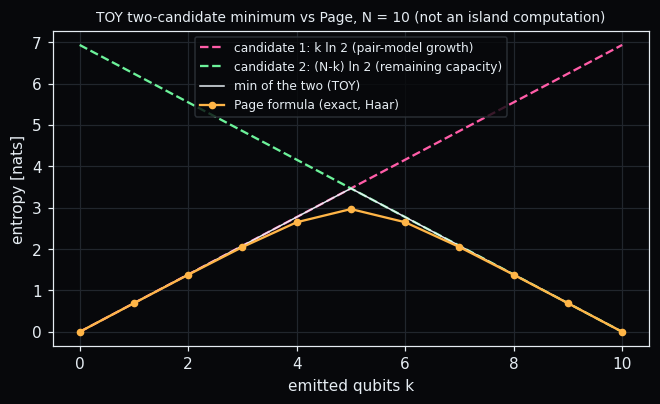

max (min-curve - Page) = 0.4994 nats at k = N/2 (-> 1/2 nat as N grows, even N)


In [9]:
N = 10; k = np.arange(N + 1); pg = np.array([page(2 ** t, 2 ** (N - t)) for t in range(N + 1)])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(k, k * LN2, "--", color=MAGENTA, label="candidate 1: k ln 2 (pair-model growth)")
ax.plot(k, (N - k) * LN2, "--", color=GREEN, label="candidate 2: (N-k) ln 2 (remaining capacity)")
ax.plot(k, np.minimum(k, N - k) * LN2, "-", color=FG, lw=1, label="min of the two (TOY)")
ax.plot(k, pg, "-o", color=AMBER, ms=4, label="Page formula (exact, Haar)")
ax.set_xlabel("emitted qubits k"); ax.set_ylabel("entropy [nats]"); ax.legend(fontsize=8); ax.grid(True)
ax.set_title("TOY two-candidate minimum vs Page, N = 10 (not an island computation)", fontsize=9); plt.show()
print(f"max (min-curve - Page) = {(np.minimum(k, N-k)*LN2 - pg).max():.4f} nats at k = N/2 (-> 1/2 nat as N grows, even N)")

In [10]:
SUMMARY["runtime_s"] = time.time() - T0
os.makedirs(RES, exist_ok=True)
json.dump(SUMMARY, open(os.path.join(RES, "notebook_summary.json"), "w"), indent=1)
print(f"total runtime {SUMMARY['runtime_s']:.1f} s; summary written to results/notebook_summary.json")

total runtime 18.9 s; summary written to results/notebook_summary.json
